# Milestone 2 - Mesurer la situation actuelle (imputation : camion plein)

**But :** décrire précisément comment les fournisseurs livrent les usines aujourd'hui, chiffrer ce que cela coûte et identifier les couples où la consolidation rapportera le plus.
La situation actuelle est la **référence (baseline)** à laquelle le moteur du Milestone 3 sera comparé (EF04).

**Entrée :** `data/consolidated_dataset_max.csv` : les poids et volumes manquants (134 poids, 116 volumes) sont complétés par un **camion plein** (24 500 kg / 110,4 m³), le choix le plus prudent de `milestone1` (`impute_quantile = None`) ; la distance manquante de SUP_00130 est complétée par la **distance maximale** des fournisseurs du planning (149 km, `distance_impute_quantile = None`). Le fichier est produit par `milestone1/preparation.ipynb` (besoins nettoyés, sans le cumul du 01/01 ni les lignes plus lourdes qu'un camion).
La colonne `rate_cost` n'est pas utilisée : le prix dépend du poids de l'**envoi complet**, pas de celui d'une ligne. Il est recalculé ici, livraison par livraison.

| Étape | Question | Règle / exigence |
| :--- | :--- | :--- |
| **1** | Données d'entrée et grille tarifaire | EF01 |
| **2** | Comment passe-t-on des lignes de besoin aux livraisons ? | RG01, RG12 |
| **3** | Combien de livraisons par couple, par usine et par semaine ? | EF04 |
| **4** | Quels poids, volume et remplissage par livraison ? | RG04 |
| **5** | Combien coûte une livraison ? (estimateur de coût) | RG11 |
| **6** | Quels indicateurs de référence ? | EF04, EF08 |
| **7** | Quels couples ont le plus de potentiel ? | EF04 |
| **8** | Export des résultats de référence | EF04 |

## Paramètres communs

In [1]:
from __future__ import annotations

import logging
import re
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from pypdf import PdfReader

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s %(levelname)-7s %(message)s",
    datefmt="%H:%M:%S",
    force=True,
)
logging.getLogger("pypdf").setLevel(logging.ERROR)
logging.getLogger("matplotlib").setLevel(logging.WARNING)
logger = logging.getLogger("baseline")


@dataclass(frozen=True)
class BaselineConfig:
    """All tunable parameters of the baseline measurement (EF12)."""

    data_dir: Path = Path("../data")
    docs_dir: Path = Path("../docs")
    output_dir: Path = Path("../data")
    imputation: str = "max"  # "median" or "max": reads consolidated_dataset_<imputation>.csv, suffixes the exports
    truck_kg: float = 24_500.0  # RG04: weight capacity of one truck
    truck_m3: float = 110.4  # RG04: volume capacity of one truck
    margin: float = 2.3923  # RG11 / EF12: freight value margin (239.23 %), as printed in rate_sheet.pdf
    diesel_surcharge: float = 1.1943  # RG11 / EF12: diesel surcharge factor, as printed in rate_sheet.pdf
    couple_key: tuple[str, ...] = ("supplier_id", "plant")  # RG01
    pareto_share_a: float = 0.80  # class A = couples carrying the first 80 % of the potential saving
    pareto_share_b: float = 0.95  # class B = up to 95 %, class C = the rest


cfg = BaselineConfig()

# Chart style: thin marks, light grid, one colour per plant (fixed order)
PLANT_COLORS = {"PLT_001": "#2a78d6", "PLT_002": "#eb6834", "PLT_003": "#1baf7a", "PLT_004": "#eda100"}
PRIMARY, MUTED, ACCENT = "#2a78d6", "#52514e", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": "#e4e3df",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))

## 1. Données d'entrée

Le dataset consolidé contient une ligne par besoin (fournisseur × material × usine × quai × jour), avec sa distance.
La grille tarifaire vient de `data/rate_sheet_long.csv`. La marge et la surcharge diesel sont des paramètres communs (`BaselineConfig`, EF12), comme dans `milestone1.ipynb` ; on vérifie qu'ils correspondent toujours au PDF.

In [2]:
needs = pd.read_csv(cfg.data_dir / f"consolidated_dataset_{cfg.imputation}.csv", parse_dates=["date"])
needs = needs.drop(columns="rate_cost", errors="ignore")  # price of a single line: not a transport cost
rate_sheet_long = pd.read_csv(cfg.data_dir / "rate_sheet_long.csv")


def read_price_factors(pdf_path: Path) -> tuple[float, float]:
    """Margin and diesel surcharge printed under the grid of the rate sheet PDF."""
    text = "\n".join(page.extract_text() or "" for page in PdfReader(pdf_path).pages)
    margin = re.search(r"margin:\s*([\d.,]+)\s*%", text)
    diesel = re.search(r"Diesel surcharge:\s*([\d.,]+)", text)
    if margin is None or diesel is None:
        raise ValueError("Rate sheet: margin or diesel surcharge not found")
    return float(margin.group(1).replace(",", ".")) / 100, float(diesel.group(1).replace(",", "."))


# EF12: margin and diesel come from the common parameters; warn if the PDF says otherwise
pdf_margin, pdf_diesel = read_price_factors(cfg.docs_dir / "rate_sheet.pdf")
if not (np.isclose(pdf_margin, cfg.margin) and np.isclose(pdf_diesel, cfg.diesel_surcharge)):
    logger.warning("Configured margin / diesel (%.4f / %.4f) differ from rate_sheet.pdf (%.4f / %.4f): "
                   "the configuration is used", cfg.margin, cfg.diesel_surcharge, pdf_margin, pdf_diesel)
MARGIN, DIESEL = cfg.margin, cfg.diesel_surcharge
PRICE_FACTOR = (1 + MARGIN) * DIESEL

assert needs[["weight", "volume", "distance"]].notna().all().all(), "missing load or distance"
assert (needs["weight"] <= cfg.truck_kg).all(), "a single line heavier than a truck (removed by DQ07)"
logger.info("Needs: %d rows, %d couples, %s -> %s", len(needs), needs.groupby(list(cfg.couple_key)).ngroups,
            needs["date"].min().date(), needs["date"].max().date())
logger.info("Rate sheet: %d cells | margin %.2f %% | diesel x%.4f | price factor x%.4f",
            len(rate_sheet_long), MARGIN * 100, DIESEL, PRICE_FACTOR)
needs.head()

10:08:46 INFO    Needs: 4389 rows, 180 couples, 2026-11-09 -> 2026-12-18


10:08:46 INFO    Rate sheet: 210 cells | margin 239.23 % | diesel x1.1943 | price factor x4.0514


,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,distance
0,2026-11-11,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00
1,2026-11-13,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00
2,2026-11-16,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00
3,2026-11-18,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00
4,2026-11-19,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00


## 2. Des lignes de besoin aux livraisons

**Définition (RG12) :** aujourd'hui, chaque fournisseur livre une usine le jour même de chaque besoin.
Une **livraison** est donc un **couple fournisseur × usine × jour** : toutes les lignes de ce jour (plusieurs *materials*, éventuellement plusieurs quais) partent dans le même envoi.
C'est aussi l'unité facturée par le transporteur : le poids qui fixe le prix est celui de l'envoi complet.

Le remplissage d'un camion est le plus élevé des deux ratios poids / 24,5 t et volume / 110,4 m³ (RG04) ; au-delà de 100 %, il faut un camion de plus.
Aucun jour férié allemand ne tombe dans l'horizon (09/11 → 18/12) : chaque jour de besoin est un jour de livraison.

In [3]:
DAYS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]


def build_deliveries(lines: pd.DataFrame) -> pd.DataFrame:
    """One row per couple x day: the load that leaves together today (RG12)."""
    deliveries = (
        lines.groupby([*cfg.couple_key, "date"])
        .agg(
            lines=("material", "size"),
            materials=("material", "nunique"),
            unloading_points=("unloading_point", "nunique"),
            weight=("weight", "sum"),
            volume=("volume", "sum"),
            distance=("distance", "first"),
        )
        .reset_index()
    )
    deliveries["week"] = deliveries["date"] - pd.to_timedelta(deliveries["date"].dt.day_of_week, unit="D")
    deliveries["weekday"] = deliveries["date"].dt.day_of_week.map(dict(enumerate(DAYS)))  # day name (lundi ... vendredi)
    deliveries["fill_weight"] = deliveries["weight"] / cfg.truck_kg
    deliveries["fill_volume"] = deliveries["volume"] / cfg.truck_m3
    deliveries["fill"] = deliveries[["fill_weight", "fill_volume"]].max(axis=1)
    deliveries["trucks"] = np.ceil(deliveries["fill"]).astype(int)
    deliveries["binding"] = np.where(deliveries["fill_weight"] >= deliveries["fill_volume"], "weight", "volume")
    return deliveries


deliveries = build_deliveries(needs)
N_WEEKS = deliveries["week"].nunique()

assert np.isclose(deliveries["weight"].sum(), needs["weight"].sum()), "weight lost in the aggregation"
assert deliveries["lines"].sum() == len(needs), "line lost in the aggregation"
logger.info("%d lines -> %d deliveries (couple x day) over %d weeks", len(needs), len(deliveries), N_WEEKS)
deliveries.head()

10:08:46 INFO    4389 lines -> 1665 deliveries (couple x day) over 6 weeks


,supplier_id,plant,date,lines,materials,unloading_points,weight,volume,distance,week,weekday,fill_weight,fill_volume,fill,trucks,binding
0,SUP_00001,PLT_004,2026-11-26,4,4,1,25 020.20,3.39,47.00,2026-11-23,jeudi,1.02,0.03,1.02,2,weight
1,SUP_00001,PLT_004,2026-11-27,1,1,1,24 500.00,0.42,47.00,2026-11-23,vendredi,1.00,0.00,1.00,1,weight
2,SUP_00001,PLT_004,2026-11-30,1,1,1,24 500.00,0.42,47.00,2026-11-30,lundi,1.00,0.00,1.00,1,weight
3,SUP_00001,PLT_004,2026-12-01,1,1,1,24 500.00,0.42,47.00,2026-11-30,mardi,1.00,0.00,1.00,1,weight
4,SUP_00001,PLT_004,2026-12-02,1,1,1,24 500.00,0.42,47.00,2026-11-30,mercredi,1.00,0.00,1.00,1,weight


## 3. Livraisons par couple, par usine et par semaine

**Calendrier des livraisons par couple :** une ligne par couple fournisseur × usine (180 lignes), une colonne par semaine.
Chaque case donne le nombre de livraisons du couple cette semaine-là (0 = aucune livraison). Une semaine à 5 = une livraison chaque jour ouvré.

La colonne **`profil`** est le **maximum observé sur une semaine** : c'est le rythme dont le couple a besoin aujourd'hui dans sa semaine la plus chargée. Exemple : 1, 1, 2, 3, 2, 1 → profil = 3 / semaine.

In [4]:
couple_week = pd.crosstab([deliveries["supplier_id"], deliveries["plant"]], deliveries["week"])
couple_week.columns = [f"sem. {w:%d/%m}" for w in couple_week.columns]
week_cols = list(couple_week.columns)
couple_week["total"] = couple_week[week_cols].sum(axis=1)
couple_week["profil"] = couple_week[week_cols].max(axis=1)  # current profile = busiest week

assert len(couple_week) == deliveries.groupby(list(cfg.couple_key)).ngroups
assert couple_week["total"].sum() == len(deliveries)
with pd.option_context("display.max_rows", len(couple_week) + 1):
    display(couple_week)

sem. 09/11  sem. 16/11  sem. 23/11  sem. 30/11  \
supplier_id plant                                                     
SUP_00001   PLT_004           0           0           2           5   
SUP_00003   PLT_001           2           0           2           2   
SUP_00005   PLT_001           0           1           1           1   
SUP_00008   PLT_002           1           0           1           1   
SUP_00009   PLT_004           0           1           0           0   
SUP_00010   PLT_001           1           0           2           1   
            PLT_002           1           2           3           1   
            PLT_004           2           2           2           2   
SUP_00011   PLT_002           2           0           3           2   
            PLT_004           5           5           5           5   
SUP_00014   PLT_001           4           1           3           4   
            PLT_004           2           2           2           2   
SUP_00015   PLT_004           0           0           1           0   
SUP_00016   PLT_001           0           1           1           1   
            PLT_002           1           0           0           0   
            PLT_003           1           0           1           0   
SUP_00018   PLT_002           0           1           1           0   
SUP_00019   PLT_001           0           1           1           0   
            PLT_002           1           2           2           1   
            PLT_004           2           3           2           2   
SUP_00020   PLT_002           0           1           2           0   
SUP_00022   PLT_004           3           2           2           2   
SUP_00024   PLT_001           3           4           2           3   
            PLT_002           0           1           3           1   
            PLT_003           1           1           1           1   
            PLT_004           5           4           3           4   
SUP_00026   PLT_001           1           1           1           1   
SUP_00028   PLT_002           0           1           2           0   
SUP_00032   PLT_002           0           1           3           1   
            PLT_004           1           3           1           2   
SUP_00033   PLT_002           0           1           2           0   
            PLT_004           3           2           2           2   
SUP_00035   PLT_001           3           3           4           1   
            PLT_002           3           3           4           3   
SUP_00037   PLT_001           1           1           1           3   
            PLT_002           3           2           4           0   
SUP_00038   PLT_001           5           5           4           4   
            PLT_002           3           3           3           3   
            PLT_003           1           1           1           1   
            PLT_004           1           1           1           1   
SUP_00039   PLT_002           0           1           2           0   
SUP_00041   PLT_004           3           5           5           3   
SUP_00043   PLT_004           2           4           3           3   
SUP_00045   PLT_001           4           5           4           4   
            PLT_002           1           1           2           2   
SUP_00046   PLT_002           0           1           2           1   
            PLT_004           1           1           1           1   
SUP_00051   PLT_001           2           2           1           3   
SUP_00052   PLT_001           5           4           4           2   
            PLT_002           0           1           0           0   
SUP_00053   PLT_001           4           4           5           4   
            PLT_002           0           1           3           1   
SUP_00054   PLT_002           0           1           1           0   
SUP_00055   PLT_001           3           4           4           2   
            PLT_003           1           0  

### 3.1 Par couple : profil actuel

Le **profil actuel** d'un couple est le nombre **maximal** de livraisons observé sur une même semaine (colonne `profil` du tableau ci-dessus).
On retient le maximum plutôt que la moyenne : un profil doit couvrir les semaines les plus chargées, et la moyenne des semaines actives (`per_week`, gardée pour information) n'est pas un nombre entier pour la moitié des couples.

Un profil de 4 livraisons par semaine n'existe pas dans les fréquences autorisées (RG05 : 1, 2, 3 ou 5) : ces couples devront passer à 3 ou à 5 au Milestone 3.

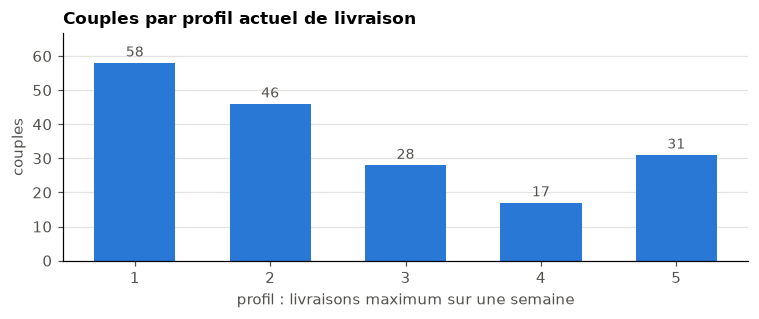

Semaines actives : {1: 20, 2: 24, 3: 25, 4: 24, 5: 30, 6: 57} (semaines -> couples)
Couples avec une seule livraison sur l'horizon : 18


,couples,livraisons,% des livraisons
profil (livraisons max / semaine),,,
1,58,164,9.85
2,46,260,15.62
3,28,256,15.38
4,17,256,15.38
5,31,729,43.78


In [5]:
couples = (
    deliveries.groupby(list(cfg.couple_key))
    .agg(deliveries=("date", "size"), active_weeks=("week", "nunique"), distance=("distance", "first"))
    .reset_index()
)
couples["per_week"] = couples["deliveries"] / couples["active_weeks"]  # average, for information
couples["profile"] = couple_week.loc[pd.MultiIndex.from_frame(couples[list(cfg.couple_key)]), "profil"].to_numpy()

freq = couples["profile"].value_counts().sort_index().rename("couples").to_frame()
freq["livraisons"] = couples.groupby("profile")["deliveries"].sum()
freq["% des livraisons"] = 100 * freq["livraisons"] / freq["livraisons"].sum()
freq.index.name = "profil (livraisons max / semaine)"

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.bar(freq.index.astype(str), freq["couples"], color=PRIMARY, width=0.6)
ax.bar_label(bars, padding=2, fontsize=9, color=MUTED)
ax.set_ylim(0, freq["couples"].max() * 1.15)  # room for the labels above the bars
ax.set_title("Couples par profil actuel de livraison")
ax.set_xlabel("profil : livraisons maximum sur une semaine"); ax.set_ylabel("couples")
plt.tight_layout(); plt.show()

print(f"Semaines actives : {couples['active_weeks'].value_counts().sort_index().to_dict()} (semaines -> couples)")
print(f"Couples avec une seule livraison sur l'horizon : {(couples['deliveries'] == 1).sum()}")
freq

### 3.2 Par usine et par semaine

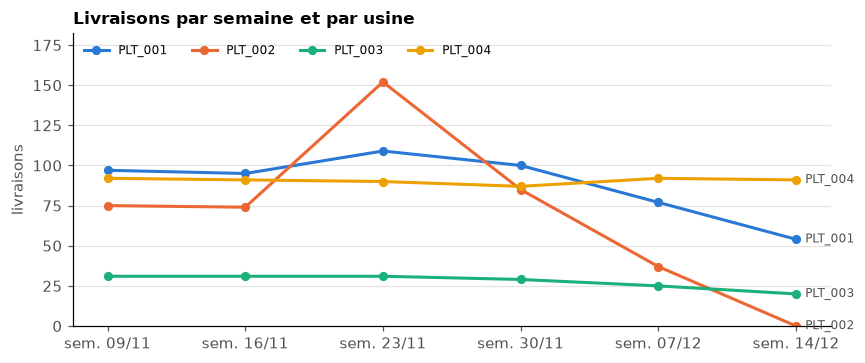

,09/11,16/11,23/11,30/11,07/12,14/12,total
plant,,,,,,,
PLT_001,97,95,109,100,77,54,532
PLT_002,75,74,152,85,37,0,423
PLT_003,31,31,31,29,25,20,167
PLT_004,92,91,90,87,92,91,543
total,295,291,382,301,231,165,1665


In [6]:
plant_week = pd.crosstab(deliveries["plant"], deliveries["week"], margins=True, margins_name="total")
plant_week.columns = [c.strftime("%d/%m") if isinstance(c, pd.Timestamp) else c for c in plant_week.columns]

weekly = deliveries.groupby(["week", "plant"]).size().unstack("plant", fill_value=0)  # a week without delivery counts as 0
fig, ax = plt.subplots(figsize=(8, 3.4))
for plant in weekly.columns:
    ax.plot(weekly.index, weekly[plant], marker="o", markersize=5, lw=2, color=PLANT_COLORS[plant], label=plant)
    ax.annotate(plant, (weekly.index[-1], weekly[plant].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=MUTED)
ax.set_xticks(weekly.index, [d.strftime("sem. %d/%m") for d in weekly.index])
ax.set_title("Livraisons par semaine et par usine")
ax.set_ylabel("livraisons"); ax.legend(ncols=4, loc="upper left", fontsize=8)
ax.set_ylim(0, weekly.max().max() * 1.2)
plt.tight_layout(); plt.show()
plant_week

### 3.3 Par jour de la semaine (point de départ du lissage)

In [7]:
days = [d for d in DAYS if d in set(deliveries["weekday"])]  # working days, in calendar order
plant_day = pd.crosstab(deliveries["plant"], deliveries["weekday"], margins=True, margins_name="total")
plant_day = plant_day[[*days, "total"]]
share = plant_day[days].div(plant_day[days].sum(axis=1), axis=0).mul(100).round(1)
share.columns = [f"% {d}" for d in days]
plant_day.join(share)

,lundi,mardi,mercredi,jeudi,vendredi,total,% lundi,% mardi,% mercredi,% jeudi,% vendredi
plant,,,,,,,,,,,
PLT_001,89,108,112,117,106,532,16.70,20.30,21.10,22.00,19.90
PLT_002,91,69,49,97,117,423,21.50,16.30,11.60,22.90,27.70
PLT_003,20,56,19,60,12,167,12.00,33.50,11.40,35.90,7.20
PLT_004,107,97,114,103,122,543,19.70,17.90,21.00,19.00,22.50
total,307,330,294,377,357,1665,18.40,19.80,17.70,22.60,21.40


## 4. Poids, volume et remplissage par livraison

In [8]:
load_cols = ["weight", "volume", "fill_weight", "fill_volume", "fill"]
dist = deliveries[load_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T
dist.index = ["poids (kg)", "volume (m³)", "remplissage poids", "remplissage volume", "remplissage (max)"]
dist

,count,mean,std,min,25%,50%,75%,90%,99%,max
poids (kg),1 665.00,2 925.80,7 848.04,0.77,137.00,349.64,1 019.80,5 608.90,26 818.79,73 500.00
volume (m³),1 665.00,9.38,31.95,0.01,0.42,1.20,2.40,6.74,112.44,331.20
remplissage poids,1 665.00,0.12,0.32,0.00,0.01,0.01,0.04,0.23,1.09,3.00
remplissage volume,1 665.00,0.08,0.29,0.00,0.00,0.01,0.02,0.06,1.02,3.00
remplissage (max),1 665.00,0.12,0.32,0.00,0.01,0.02,0.04,0.23,1.09,3.00


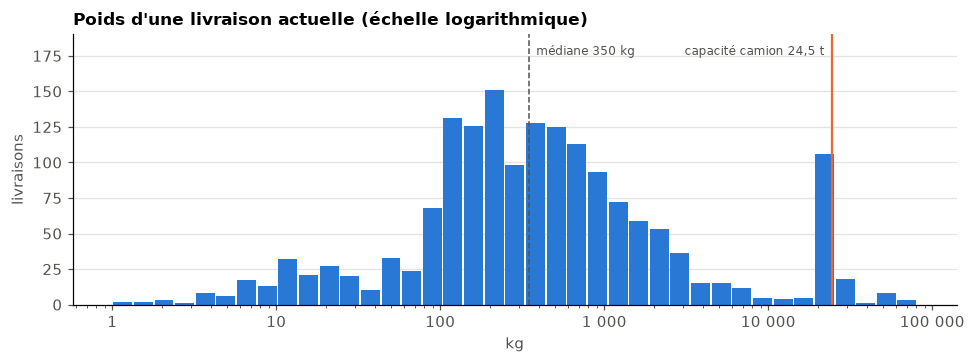

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.logspace(0, np.log10(deliveries["weight"].max() * 1.1), 40)
ax.hist(deliveries["weight"], bins=bins, color=PRIMARY, rwidth=0.92)
ax.set_xscale("log")
y_top = ax.get_ylim()[1] * 1.2
ax.set_ylim(0, y_top)
median_w = deliveries["weight"].median()
ax.axvline(cfg.truck_kg, color=ACCENT, lw=1.5)
ax.text(cfg.truck_kg * 0.9, y_top * 0.96, "capacité camion 24,5 t", ha="right", va="top", fontsize=8, color=MUTED)
ax.axvline(median_w, color=MUTED, lw=1, ls="--")
ax.text(median_w * 1.1, y_top * 0.96, f"médiane {median_w:.0f} kg", va="top", fontsize=8, color=MUTED)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " ")))
ax.set_title("Poids d'une livraison actuelle (échelle logarithmique)")
ax.set_xlabel("kg"); ax.set_ylabel("livraisons")
plt.tight_layout(); plt.show()

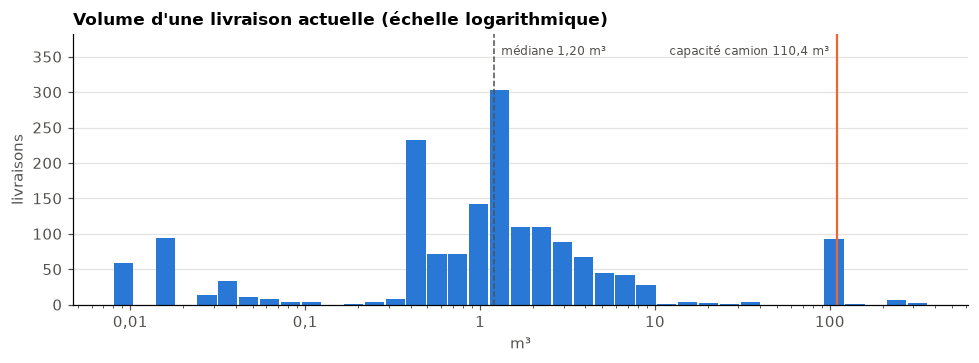

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.4))
v_min, v_max = deliveries["volume"].min(), max(deliveries["volume"].max(), cfg.truck_m3)
bins = np.logspace(np.log10(v_min * 0.9), np.log10(v_max * 1.1), 40)
ax.hist(deliveries["volume"], bins=bins, color=PRIMARY, rwidth=0.92)
ax.set_xscale("log")
y_top = ax.get_ylim()[1] * 1.2
ax.set_ylim(0, y_top)
median_v = deliveries["volume"].median()
ax.axvline(cfg.truck_m3, color=ACCENT, lw=1.5)
ax.text(cfg.truck_m3 * 0.9, y_top * 0.96, "capacité camion 110,4 m³", ha="right", va="top", fontsize=8, color=MUTED)
ax.axvline(median_v, color=MUTED, lw=1, ls="--")
ax.text(median_v * 1.1, y_top * 0.96, f"médiane {median_v:.2f} m³".replace(".", ","), va="top", fontsize=8, color=MUTED)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}".replace(".", ",")))
ax.set_title("Volume d'une livraison actuelle (échelle logarithmique)")
ax.set_xlabel("m³"); ax.set_ylabel("livraisons")
plt.tight_layout(); plt.show()

In [11]:
by_plant = deliveries.groupby("plant").agg(
    livraisons=("date", "size"),
    poids_median_kg=("weight", "median"),
    volume_median_m3=("volume", "median"),
    remplissage_median=("fill", "median"),
    remplissage_p90=("fill", lambda s: s.quantile(0.9)),
    part_volume_limitant=("binding", lambda s: (s == "volume").mean()),
)
by_plant["remplissage_median"] *= 100
by_plant["remplissage_p90"] *= 100
by_plant["part_volume_limitant"] *= 100

print(f"Contrainte limitante : poids {(deliveries['binding'] == 'weight').mean():.0%} | "
      f"volume {(deliveries['binding'] == 'volume').mean():.0%}")
print(f"Livraisons de plus d'un camion : {(deliveries['trucks'] > 1).sum()} "
      f"| livraisons ≤ 1 000 kg : {(deliveries['weight'] <= 1000).mean():.0%}")
by_plant.rename(columns={"remplissage_median": "remplissage médian (%)", "remplissage_p90": "remplissage P90 (%)",
                         "part_volume_limitant": "volume limitant (%)"})

Contrainte limitante : poids 70% | volume 30%
Livraisons de plus d'un camion : 70 | livraisons ≤ 1 000 kg : 75%


,livraisons,poids_median_kg,volume_median_m3,remplissage médian (%),remplissage P90 (%),volume limitant (%)
plant,,,,,,
PLT_001,532,243.30,0.57,1.03,8.07,13.72
PLT_002,423,307.94,1.20,1.40,100.00,39.48
PLT_003,167,595.74,1.20,2.43,101.65,7.78
PLT_004,543,442.50,1.30,2.12,10.44,46.04


**Lecture :** une livraison typique pèse environ 350 kg et remplit 1 à 2 % d'un camion ; 75 % des livraisons pèsent 1 000 kg ou moins.
Les lignes complétées par un camion plein gonflent le haut de la distribution : 90 % des livraisons remplissent moins de 23 % d'un camion, mais **70 livraisons dépassent un camion** (4 seulement avec l'imputation par la médiane).
Le poids est la contrainte limitante dans 70 % des livraisons, le volume dans 30 % : les deux limites doivent être suivies par le moteur.

## 5. Estimateur de coût (RG11)

**Règle :** le prix d'un envoi se lit dans la grille avec la **distance du fournisseur** (ligne) et le **poids total de l'envoi** (colonne), puis :

`prix = coût de base × (1 + marge) × surcharge diesel`

- Les bornes de la grille sont des maxima inclusifs (« up to ») : 121 km se lit sur la ligne ≤ 125 km.
- Au-delà de 4 000 kg, le tarif est forfaitaire (colonne `> 4000`).
- **Livraison de plus d'un camion :** on remplit d'abord des camions **pleins** (jusqu'à 24,5 t ou 110,4 m³, la première limite atteinte), puis le **reste** part dans un dernier camion. Chaque camion est un envoi facturé selon son propre poids : le dernier, plus léger, tombe souvent dans une tranche moins chère.
  Exemple : 25 723 kg → un camion de 24 500 kg (tarif > 4 000 kg) + un camion de 1 223 kg (tarif ≤ 1 500 kg).

In [12]:
KM_BOUNDS = np.sort(rate_sheet_long["km_max"].unique())
KG_BOUNDS = np.sort(rate_sheet_long["kg_max"].unique())
GRID = rate_sheet_long.pivot(index="km_max", columns="kg_max", values="base_cost")


def bracket(values, bounds: np.ndarray) -> np.ndarray:
    """Smallest bound >= value: the bounds of the rate sheet are inclusive maxima."""
    position = np.searchsorted(bounds, np.asarray(values, dtype=float), side="left")
    if (position >= len(bounds)).any():
        raise ValueError("value outside the rate sheet")
    return bounds[position]


def truck_price(distance_km, weight_kg) -> np.ndarray:
    """Price in EUR of ONE truck: grid(distance, weight) x (1 + margin) x diesel (RG11)."""
    km = bracket(distance_km, KM_BOUNDS)
    kg = bracket(weight_kg, KG_BOUNDS)
    return GRID.to_numpy()[np.searchsorted(GRID.index, km), np.searchsorted(GRID.columns, kg)] * PRICE_FACTOR


def shipment_cost(distance_km, weight_kg, volume_m3=0.0) -> np.ndarray:
    """Transport price in EUR of one shipment (vectorised).

    Full trucks first (filled up to the first limit reached, 24.5 t or 110.4 m3), then one last
    truck with the rest; each truck is invoiced as one shipment on its own weight.
    """
    weight = np.asarray(weight_kg, dtype=float)
    fill = np.maximum(weight / cfg.truck_kg, np.asarray(volume_m3, dtype=float) / cfg.truck_m3)
    trucks = np.maximum(np.ceil(fill), 1)
    full_truck_weight = np.divide(weight, fill, out=weight.copy(), where=fill > 1)  # weight carried by one full truck
    last_truck_weight = weight - (trucks - 1) * full_truck_weight
    return (trucks - 1) * truck_price(distance_km, full_truck_weight) + truck_price(distance_km, last_truck_weight)


deliveries["cost"] = shipment_cost(deliveries["distance"], deliveries["weight"], deliveries["volume"])
logger.info("Baseline cost: %.0f EUR for %d deliveries", deliveries["cost"].sum(), len(deliveries))

10:08:47 INFO    Baseline cost: 176979 EUR for 1665 deliveries


## 6. Indicateurs de référence (baseline)

Ce sont les valeurs à battre au Milestone 3. Le coût est recalculé envoi par envoi avec l'estimateur ci-dessus.

In [13]:
def kpis(d: pd.DataFrame) -> pd.Series:
    """Baseline indicators of a set of deliveries."""
    return pd.Series({
        "couples": d.groupby(list(cfg.couple_key)).ngroups,
        "livraisons": len(d),
        "camions": int(d["trucks"].sum()),
        "poids total (t)": d["weight"].sum() / 1000,
        "poids médian d'une livraison (kg)": d["weight"].median(),
        "remplissage poids médian (%)": 100 * d["fill_weight"].median(),
        "volume médian d'une livraison (m³)": d["volume"].median(),
        "remplissage volume médian (%)": 100 * d["fill_volume"].median(),
        "coût total (EUR)": d["cost"].sum(),
    })


baseline_kpis = pd.concat({"total": kpis(deliveries), **{p: kpis(g) for p, g in deliveries.groupby("plant")}}, axis=1)
baseline_kpis

,total,PLT_001,PLT_002,PLT_003,PLT_004
couples,180.00,51.00,64.00,26.00,39.00
livraisons,1 665.00,532.00,423.00,167.00,543.00
camions,1 744.00,540.00,452.00,193.00,559.00
poids total (t),4 871.46,920.12,1 652.63,879.10,1 419.60
poids médian d'une livraison (kg),349.64,243.30,307.94,595.74,442.50
remplissage poids médian (%),1.43,0.99,1.26,2.43,1.81
volume médian d'une livraison (m³),1.20,0.57,1.20,1.20,1.30
remplissage volume médian (%),1.09,0.52,1.09,1.09,1.18
coût total (EUR),176 979.32,45 200.68,45 170.05,27 931.81,58 676.77


In [14]:
cost_week = deliveries.pivot_table(index="plant", columns="week", values="cost", aggfunc="sum", fill_value=0)
cost_week.columns = [c.strftime("%d/%m") for c in cost_week.columns]
cost_week.loc["total"] = cost_week.sum()
cost_week.round(0)

,09/11,16/11,23/11,30/11,07/12,14/12
plant,,,,,,
PLT_001,7 991.00,7 999.00,8 391.00,8 915.00,7 071.00,4 834.00
PLT_002,8 183.00,7 575.00,16 787.00,8 629.00,3 996.00,0.00
PLT_003,4 816.00,5 821.00,5 119.00,4 043.00,4 617.00,3 515.00
PLT_004,10 961.00,10 248.00,9 356.00,9 573.00,9 106.00,9 432.00
total,31 950.00,31 643.00,39 654.00,31 160.00,24 790.00,17 782.00


**Lecture :** le coût est élevé au regard du poids transporté parce que la grande majorité des envois sont légers, là où le tarif au kilo est le plus cher (la grille est très dégressive avec le poids, puis forfaitaire au-delà de 4 t).
Faire baisser le **nombre d'envois** est donc le levier principal.

## 7. Classement des couples selon leur potentiel

**Méthode :** pour mesurer le potentiel de chaque couple, on chiffre un scénario simple : **une seule livraison par semaine**, qui regroupe tous les besoins de la semaine.
C'est la fréquence la plus basse autorisée (RG05). Elle donne une **borne indicative** du saving, pas la solution : le Milestone 3 ajoutera les jours fixes, le lissage et la préférence du client pour ajouter des jours de livraison plutôt que des camions.

Le potentiel d'un couple = coût actuel − coût du scénario. Les couples sont ensuite classés en **A / B / C** selon leur part cumulée du saving (A : 80 % du potentiel, B : jusqu'à 95 %, C : le reste).

In [15]:
weekly_load = (
    deliveries.groupby([*cfg.couple_key, "week"])
    .agg(weight=("weight", "sum"), volume=("volume", "sum"), distance=("distance", "first"))
    .reset_index()
)
weekly_load["trucks"] = np.ceil(np.maximum(weekly_load["weight"] / cfg.truck_kg, weekly_load["volume"] / cfg.truck_m3)).astype(int)
weekly_load["cost"] = shipment_cost(weekly_load["distance"], weekly_load["weight"], weekly_load["volume"])

current = deliveries.groupby(list(cfg.couple_key)).agg(current_cost=("cost", "sum"), weight=("weight", "sum"),
                                                        median_fill=("fill", "median"))
scenario = weekly_load.groupby(list(cfg.couple_key)).agg(weekly_cost=("cost", "sum"), weekly_deliveries=("week", "size"),
                                                         weekly_trucks=("trucks", "sum"))
ranking = couples.set_index(list(cfg.couple_key)).join(current).join(scenario)
ranking["saving"] = ranking["current_cost"] - ranking["weekly_cost"]
ranking["saving_pct"] = 100 * ranking["saving"] / ranking["current_cost"]
ranking = ranking.sort_values("saving", ascending=False)
ranking["rank"] = np.arange(1, len(ranking) + 1)
ranking["cum_share"] = ranking["saving"].cumsum() / ranking["saving"].sum()
ranking["potential_class"] = np.select(
    [ranking["cum_share"].shift(fill_value=0) < cfg.pareto_share_a,
     ranking["cum_share"].shift(fill_value=0) < cfg.pareto_share_b], ["A", "B"], "C")
ranking = ranking.reset_index()

assert (ranking["saving"] >= -0.01).all(), "grouping a week should never cost more than delivering daily"
summary = ranking.groupby("potential_class").agg(couples=("rank", "size"), saving_eur=("saving", "sum"),
                                                 current_cost_eur=("current_cost", "sum"))
summary["% du saving"] = 100 * summary["saving_eur"] / summary["saving_eur"].sum()
logger.info("Weekly scenario: %.0f EUR -> %.0f EUR (-%.0f %%)", ranking["current_cost"].sum(),
            ranking["weekly_cost"].sum(), 100 * ranking["saving"].sum() / ranking["current_cost"].sum())
logger.info("Potential saving: %.0f EUR over %d weeks", ranking["saving"].sum(), N_WEEKS)
summary

10:08:47 INFO    Weekly scenario: 176979 EUR -> 121406 EUR (-31 %)


10:08:47 INFO    Potential saving: 55574 EUR over 6 weeks


,couples,saving_eur,current_cost_eur,% du saving
potential_class,,,,
A,40,44 826.01,99 019.47,80.66
B,34,8 040.86,31 843.14,14.47
C,106,2 706.92,46 116.71,4.87


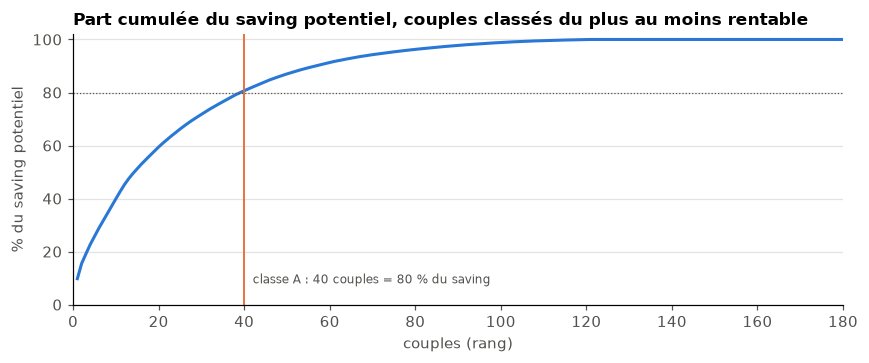

,rank,supplier_id,plant,distance,profil (/ sem.),deliveries,remplissage médian (%),coût actuel (EUR),coût 1 / semaine (EUR),saving (EUR),saving (%),classe
0,1,SUP_00085,PLT_004,121.00,5,30,9.92,7 429.18,1 988.44,5 440.74,73.23,A
1,2,SUP_00146,PLT_002,122.00,5,20,10.46,4 651.48,1 472.49,3 178.99,68.34,A
2,3,SUP_00059,PLT_003,122.00,5,25,2.43,3 874.58,1 859.00,2 015.58,52.02,A
3,4,SUP_00144,PLT_001,38.00,5,20,10.96,3 454.61,1 497.41,1 957.20,56.65,A
4,5,SUP_00080,PLT_004,40.00,5,29,4.35,2 989.46,1 276.40,1 713.06,57.30,A
5,6,SUP_00118,PLT_001,100.00,5,29,2.11,3 210.51,1 540.68,1 669.83,52.01,A
6,7,SUP_00129,PLT_003,84.00,5,27,102.85,10 143.87,8 590.03,1 553.84,15.32,A
7,8,SUP_00149,PLT_004,13.00,5,30,3.17,2 516.99,963.75,1 553.23,61.71,A
8,9,SUP_00087,PLT_004,98.00,5,28,2.98,2 995.95,1 446.40,1 549.55,51.72,A
9,10,SUP_00011,PLT_004,145.00,5,30,1.32,2 861.52,1 320.68,1 540.84,53.85,A


In [16]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(ranking["rank"], 100 * ranking["cum_share"], color=PRIMARY, lw=2)
n_a = (ranking["potential_class"] == "A").sum()
ax.axhline(100 * cfg.pareto_share_a, color=MUTED, lw=0.8, ls=":")
ax.axvline(n_a, color=ACCENT, lw=1.2)
ax.text(n_a + 2, 8, f"classe A : {n_a} couples = {100 * cfg.pareto_share_a:.0f} % du saving", fontsize=8, color=MUTED)
ax.set_xlim(0, len(ranking)); ax.set_ylim(0, 102)
ax.set_title("Part cumulée du saving potentiel, couples classés du plus au moins rentable")
ax.set_xlabel("couples (rang)"); ax.set_ylabel("% du saving potentiel")
plt.tight_layout(); plt.show()

cols = ["rank", "supplier_id", "plant", "distance", "profile", "deliveries", "median_fill",
        "current_cost", "weekly_cost", "saving", "saving_pct", "potential_class"]
top = ranking[cols].head(40).copy()
top["median_fill"] *= 100
top.rename(columns={"profile": "profil (/ sem.)", "median_fill": "remplissage médian (%)",
                    "current_cost": "coût actuel (EUR)", "weekly_cost": "coût 1 / semaine (EUR)",
                    "saving": "saving (EUR)", "saving_pct": "saving (%)", "potential_class": "classe"})

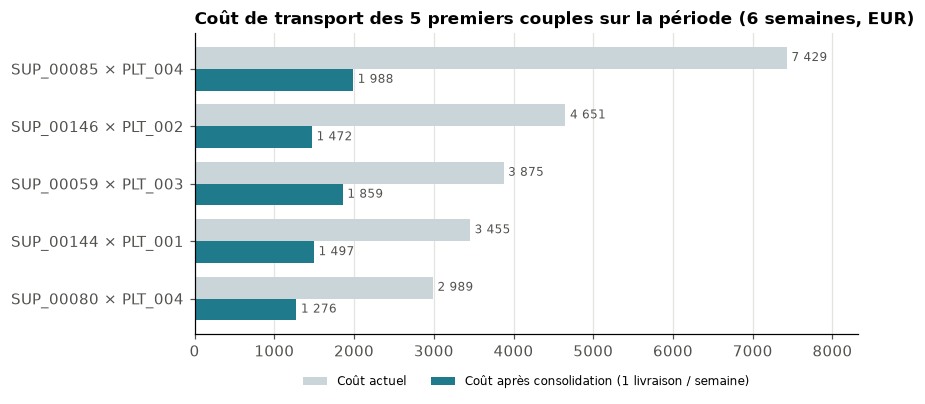

5 premiers couples, sur 6 semaines : 22 399 EUR -> 8 094 EUR (-14 306 EUR, -64 %)


,,coût actuel (EUR),coût après consolidation (EUR)
supplier_id,plant,,
SUP_00085,PLT_004,7 429.00,1 988.00
SUP_00146,PLT_002,4 651.00,1 472.00
SUP_00059,PLT_003,3 875.00,1 859.00
SUP_00144,PLT_001,3 455.00,1 497.00
SUP_00080,PLT_004,2 989.00,1 276.00


In [17]:
top5 = ranking.head(5).set_index(list(cfg.couple_key))
comparison = top5[["current_cost", "weekly_cost"]].rename(columns={
    "current_cost": "coût actuel (EUR)", "weekly_cost": "coût après consolidation (EUR)"})

fig, ax = plt.subplots(figsize=(8, 3.8))
y, h = np.arange(len(comparison)), 0.38
before = ax.barh(y - h / 2, comparison.iloc[:, 0], height=h, color="#c9d5d9", label="Coût actuel")
after = ax.barh(y + h / 2, comparison.iloc[:, 1], height=h, color="#1f7a8c", label="Coût après consolidation (1 livraison / semaine)")
for bars in (before, after):
    ax.bar_label(bars, labels=[f"{v:,.0f}".replace(",", " ") for v in bars.datavalues], padding=3, fontsize=8, color=MUTED)
ax.set_yticks(y, [f"{s} × {p}" for s, p in comparison.index])
ax.invert_yaxis()  # rank 1 at the top
ax.grid(False); ax.xaxis.grid(True, color="#e4e3df")
ax.set_xlim(0, comparison.to_numpy().max() * 1.12)
ax.set_title(f"Coût de transport des 5 premiers couples sur la période ({N_WEEKS} semaines, EUR)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=2, fontsize=8)
plt.tight_layout(); plt.show()

total_before, total_after = comparison.sum()
eur = lambda x: f"{x:,.0f}".replace(",", " ")  # thousands separated by a space
print(f"5 premiers couples, sur {N_WEEKS} semaines : {eur(total_before)} EUR -> {eur(total_after)} EUR "
      f"(-{eur(total_before - total_after)} EUR, -{100 * (1 - total_after / total_before):.0f} %)")
comparison.round(0)

**Lecture :** le potentiel est très concentré. **40 couples (classe A) portent 80 % du saving potentiel** ; tous ont un profil d'au moins 2 livraisons par semaine, 38 d'entre eux de 3 à 5, et 26 livrent tous les jours certaines semaines. Ce sont eux que le moteur du Milestone 3 doit traiter en priorité.
Les 106 couples de classe C ont surtout un profil de 1 (58 couples) ou 2 (34 couples) livraisons par semaine : ils ne représentent que 5 % du saving.

### Avant / après : les camions dans la grille tarifaire

Chaque **camion** est placé dans la case de la grille qui fixe son prix : la ligne selon la distance du fournisseur, la colonne selon le poids du camion.
Une livraison de plus d'un camion compte pour plusieurs camions, répartis comme dans l'estimateur de coût (camions pleins d'abord, puis le reste).
**Avant** = situation actuelle (un envoi par jour de besoin) ; **après** = scénario « 1 livraison par semaine ». Les deux cartes ont la même échelle de couleur.

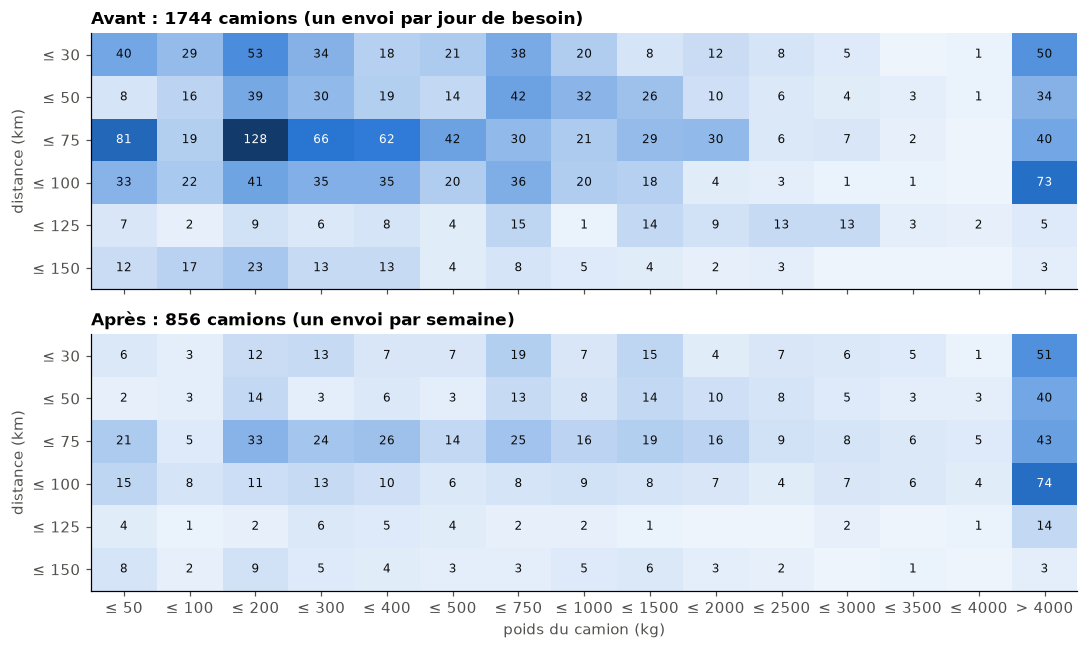

,avant,après
camions,1 744.00,856.00
poids médian d'un camion (kg),367.40,919.30
camions ≤ 1 000 kg (%),74.00,50.80
"camions > 4 000 kg, tarif forfaitaire (%)",11.80,26.30


In [18]:
from matplotlib.colors import LinearSegmentedColormap


def truck_loads(shipments: pd.DataFrame) -> pd.DataFrame:
    """One row per truck, split as in shipment_cost: full trucks first, then one truck with the rest."""
    weight = shipments["weight"].to_numpy(dtype=float)
    distance = shipments["distance"].to_numpy(dtype=float)
    fill = np.maximum(weight / cfg.truck_kg, shipments["volume"].to_numpy(dtype=float) / cfg.truck_m3)
    trucks = np.maximum(np.ceil(fill), 1).astype(int)
    full = np.divide(weight, fill, out=weight.copy(), where=fill > 1)
    last = weight - (trucks - 1) * full
    return pd.DataFrame({
        "distance": np.concatenate([np.repeat(distance, trucks - 1), distance]),
        "weight": np.concatenate([np.repeat(full, trucks - 1), last]),
    })


def grid_counts(trucks: pd.DataFrame) -> pd.DataFrame:
    """Number of trucks in each cell of the rate sheet (km bracket x kg bracket)."""
    return pd.crosstab(bracket(trucks["distance"], KM_BOUNDS), bracket(trucks["weight"], KG_BOUNDS))


trucks_before, trucks_after = truck_loads(deliveries), truck_loads(weekly_load)
rows = sorted(set(bracket(trucks_before["distance"], KM_BOUNDS)) | set(bracket(trucks_after["distance"], KM_BOUNDS)))
grids = {name: grid_counts(t).reindex(index=rows, columns=KG_BOUNDS, fill_value=0)
         for name, t in [("before", trucks_before), ("after", trucks_after)]}
assert grids["before"].to_numpy().sum() == len(trucks_before) and grids["after"].to_numpy().sum() == len(trucks_after)

cmap = LinearSegmentedColormap.from_list("seq", ["#eef4fc", PRIMARY, "#123a6b"])
vmax = max(g.to_numpy().max() for g in grids.values())  # same colour scale for both maps
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
titles = {"before": f"Avant : {len(trucks_before)} camions (un envoi par jour de besoin)",
          "after": f"Après : {len(trucks_after)} camions (un envoi par semaine)"}
for ax, (name, grid) in zip(axes, grids.items()):
    ax.imshow(grid.to_numpy(), cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    for r in range(grid.shape[0]):
        for c in range(grid.shape[1]):
            v = grid.iat[r, c]
            if v:
                ax.text(c, r, v, ha="center", va="center", fontsize=8, color="white" if v > vmax * 0.45 else "#0b0b0b")
    ax.set_yticks(range(len(rows)), [f"≤ {k:g}" for k in rows])
    ax.set_ylabel("distance (km)")
    ax.set_title(titles[name])
    ax.grid(False)
axes[-1].set_xticks(range(len(KG_BOUNDS)), [f"≤ {k:g}" if np.isfinite(k) else "> 4000" for k in KG_BOUNDS])
axes[-1].set_xlabel("poids du camion (kg)")
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    name: {"camions": len(t), "poids médian d'un camion (kg)": t["weight"].median(),
           "camions ≤ 1 000 kg (%)": 100 * (t["weight"] <= 1000).mean(),
           "camions > 4 000 kg, tarif forfaitaire (%)": 100 * (t["weight"] > 4000).mean()}
    for name, t in [("avant", trucks_before), ("après", trucks_after)]})
summary.round(1)

**Lecture :** regrouper les besoins de la semaine fait glisser les camions **vers la droite de la grille**, là où le prix au kilo est le plus bas.
Il y a 2 fois moins de camions (1 744 → 856), leur poids médian est multiplié par 2,5 (367 → 919 kg), la part des camions légers (≤ 1 000 kg) passe de 74 % à 51 % et celle des camions au tarif forfaitaire (> 4 000 kg) de 12 % à 26 %.
C'est ce déplacement qui produit le saving de 31 %. La moitié des camions restent pourtant légers : un envoi par semaine réduit surtout le **nombre** de camions, il ne suffit pas à les remplir.

## 8. Résultat et export

| Fichier | Une ligne = | Usage |
| :--- | :--- | :--- |
| `baseline_deliveries_max.csv` | une livraison actuelle (couple × jour), avec charge, remplissage et coût | référence détaillée pour le Milestone 3 |
| `baseline_couples_max.csv` | un couple, avec fréquence, coût actuel, potentiel et classe A / B / C | classement des couples |
| `baseline_kpis_max.csv` | un indicateur, au total et par usine | indicateurs de référence |

In [19]:
cfg.output_dir.mkdir(parents=True, exist_ok=True)
deliveries.to_csv(cfg.output_dir / f"baseline_deliveries_{cfg.imputation}.csv", index=False, date_format="%Y-%m-%d")
ranking.to_csv(cfg.output_dir / f"baseline_couples_{cfg.imputation}.csv", index=False)
baseline_kpis.to_csv(cfg.output_dir / f"baseline_kpis_{cfg.imputation}.csv", index_label="indicator")
logger.info("Files written to %s", cfg.output_dir.resolve().name)

pd.DataFrame({
    "fichier": [f"baseline_{n}_{cfg.imputation}.csv" for n in ("deliveries", "couples", "kpis")],
    "lignes": [len(deliveries), len(ranking), len(baseline_kpis)],
}).set_index("fichier")

10:08:47 INFO    Files written to data


,lignes
fichier,
baseline_deliveries_max.csv,1665
baseline_couples_max.csv,180
baseline_kpis_max.csv,9


## Synthèse

- **Situation actuelle :** 1 665 livraisons en 6 semaines pour 180 couples, chacune le jour même du besoin ; poids médian 350 kg, remplissage médian 1,6 %.
- **Coût de référence : 176 979 € sur 6 semaines (≈ 29 500 € par semaine)**, recalculé envoi par envoi avec un estimateur validé sur les exemples des documents du projet.
- **Potentiel :** livrer une fois par semaine ramènerait le coût à environ 121 000 € (**−31 %**, borne indicative). 40 couples (classe A) portent 80 % de ce gain.
- **Comparaison avec l'imputation par la médiane** (`situation_actuelle_median.ipynb`) : 149 216 € et −39 %. L'écart vient des 134 poids et 116 volumes complétés par un camion plein : cette référence est plus prudente pour la capacité des camions, mais elle gonfle le coût actuel.
- **Pour le Milestone 3 :** réutiliser `shipment_cost` pour chiffrer chaque solution, et commencer par les couples de classe A.